# TRABAJO ORDINARIA BIOINFORMÁTICA R
**Análisis de expresión diferencial · RNA-seq (TPM) · 619 genes · 3 Control vs 3 Condición — Versión 2**

## 0. Configuración, dependencias y utilidades

In [1]:
set.seed(20262027)
if (!isTRUE(l10n_info()$`UTF-8`)) invisible(suppressWarnings(Sys.setlocale("LC_CTYPE", "C.UTF-8")))
options(stringsAsFactors = FALSE, width = 200, warn = 1,
        repr.matrix.max.rows = 200, repr.matrix.max.cols = 30)

CONFIG <- list(
  archivo       = "archivo-entrada.txt",
  url_respaldo  = paste0("https://raw.githubusercontent.com/ismabilon/",
                         "Bioinformatica_Biomedicina_4to-Curso_2026-2027/main/",
                         "R/Entregas/Trabajo%20Final%20R/archivo-entrada.txt"),
  col_gen       = "Gene Name",
  control       = c("C1-TPM", "C2-TPM", "C3-TPM"),
  condicion     = c("1W5-TPM", "1W6-TPM", "1W5-COV"),
  alpha         = 0.05,
  pseudo        = 1,
  col_control   = "#2E86C1",
  col_condicion = "#E67E22",
  dir_fig       = file.path("resultados", "figuras"),
  dir_tab       = file.path("resultados", "tablas")
)

In [2]:
cargar_paquetes <- function(paquetes, repos = "https://cloud.r-project.org") {
  faltan <- paquetes[!vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)]
  if (length(faltan) > 0) {
    tryCatch(
      install.packages(faltan, repos = repos, quiet = TRUE),
      error = function(e) stop("No se pudieron instalar: ", paste(faltan, collapse = ", "),
                               " (", conditionMessage(e), ")", call. = FALSE)
    )
  }
  for (p in paquetes) {
    ok <- suppressPackageStartupMessages(require(p, character.only = TRUE, quietly = TRUE))
    if (!ok) stop("El paquete '", p, "' no está disponible.", call. = FALSE)
  }
  invisible(vapply(paquetes, function(p) as.character(packageVersion(p)), character(1)))
}

In [3]:
versiones <- cargar_paquetes(c("data.table", "ggplot2", "patchwork", "gplots",
                               "RColorBrewer", "ggrepel", "knitr"))
versiones

invisible(lapply(c(CONFIG$dir_fig, CONFIG$dir_tab), dir.create,
                 recursive = TRUE, showWarnings = FALSE))

en_jupyter <- function() isTRUE(getOption("jupyter.in_kernel")) && requireNamespace("IRdisplay", quietly = TRUE)

guardar_ggplot <- function(grafico, nombre, ancho, alto) {
  for (ext in c("png", "pdf")) {
    ggsave(file.path(CONFIG$dir_fig, paste0(nombre, ".", ext)), grafico,
           width = ancho, height = alto, dpi = 300, bg = "white")
  }
  if (en_jupyter()) {
    vista <- tempfile(fileext = ".png")
    ggsave(vista, grafico, width = ancho, height = alto, dpi = 110, bg = "white")
    IRdisplay::display_png(file = vista)
  } else if (interactive()) {
    print(grafico)
  }
  invisible(grafico)
}

data.table      ggplot2    patchwork       gplots RColorBrewer      ggrepel        knitr 
   "1.14.10"      "3.4.4"      "1.2.0"    "3.1.3.1"      "1.1.3"      "0.9.5"       "1.45"

In [4]:
guardar_base <- function(dibujar, nombre, ancho, alto) {
  png(file.path(CONFIG$dir_fig, paste0(nombre, ".png")),
      width = ancho, height = alto, units = "in", res = 300)
  tryCatch(dibujar(), finally = dev.off())
  pdf(file.path(CONFIG$dir_fig, paste0(nombre, ".pdf")), width = ancho, height = alto)
  tryCatch(dibujar(), finally = dev.off())
  if (en_jupyter()) {
    vista <- tempfile(fileext = ".png")
    png(vista, width = ancho, height = alto, units = "in", res = 110)
    tryCatch(dibujar(), finally = dev.off())
    IRdisplay::display_png(file = vista)
  } else if (interactive()) {
    dibujar()
  }
  invisible(NULL)
}

In [5]:
leyenda_sup_izq <- function() {
  if (packageVersion("ggplot2") >= "3.5.0") {
    theme(legend.position = "inside", legend.position.inside = c(0.02, 0.98),
          legend.justification = c(0, 1))
  } else {
    theme(legend.position = c(0.02, 0.98), legend.justification = c(0, 1))
  }
}

tema <- theme_bw(base_size = 12) +
  theme(plot.title = element_text(face = "bold"),
        plot.subtitle = element_text(colour = "grey30"),
        panel.grid.minor = element_blank(),
        legend.background = element_rect(fill = alpha("white", 0.85), colour = "grey80"))

In [6]:
colores_grupo <- c(Control = CONFIG$col_control, "Condición" = CONFIG$col_condicion)

leer_datos <- function(ruta, url) {
  fuente <- if (file.exists(ruta)) ruta else {
    message("No se encuentra '", ruta, "' en ", getwd(), "; se descarga del repositorio.")
    url
  }
  tryCatch(
    fread(fuente, sep = "\t", header = TRUE, check.names = FALSE, encoding = "UTF-8",
          strip.white = TRUE, blank.lines.skip = TRUE),
    error = function(e) stop("No se pudo leer el archivo de entrada: ", conditionMessage(e),
                             call. = FALSE)
  )
}

In [7]:
validar_datos <- function(dt, col_gen, columnas) {
  faltan <- setdiff(c(col_gen, columnas), names(dt))
  if (length(faltan) > 0) stop("Faltan columnas: ", paste(faltan, collapse = ", "), call. = FALSE)
  dt <- dt[!is.na(get(col_gen)) & nzchar(trimws(get(col_gen)))]
  for (col in columnas) {
    if (!is.numeric(dt[[col]])) set(dt, j = col, value = suppressWarnings(as.numeric(dt[[col]])))
  }
  m <- as.matrix(dt[, ..columnas])
  if (anyNA(m))                   stop("Hay valores no numéricos o ausentes.", call. = FALSE)
  if (any(m < 0))                 stop("Hay valores de TPM negativos.", call. = FALSE)
  if (anyDuplicated(dt[[col_gen]])) stop("Hay nombres de gen duplicados.", call. = FALSE)
  setcolorder(dt, c(col_gen, columnas))
  dt[]
}

In [8]:
de_filas <- function(m) sqrt(rowSums((m - rowMeans(m))^2) / (ncol(m) - 1))

shapiro_seguro <- function(x) {
  if (sd(x) == 0) return(NA_real_)
  tryCatch(shapiro.test(x)$p.value, error = function(e) NA_real_)
}

comparar_gen <- function(x, y, alpha) {
  p_sx <- shapiro_seguro(x)
  p_sy <- shapiro_seguro(y)
  normal <- !is.na(p_sx) && !is.na(p_sy) && p_sx > alpha && p_sy > alpha
  if (normal) {
    p_var <- var.test(x, y)$p.value
    var_igual <- p_var > alpha
    prueba <- t.test(x, y, var.equal = var_igual)
    c(p_sx, p_sy, p_var, if (var_igual) 1 else 2, unname(prueba$statistic), prueba$p.value)
  } else {
    prueba <- suppressWarnings(wilcox.test(x, y, exact = FALSE))
    c(p_sx, p_sy, NA_real_, 3, unname(prueba$statistic), prueba$p.value)
  }
}

In [9]:
welch_vectorizado <- function(a, b) {
  na <- ncol(a); nb <- ncol(b)
  va <- de_filas(a)^2 / na; vb <- de_filas(b)^2 / nb
  t  <- (rowMeans(b) - rowMeans(a)) / sqrt(va + vb)
  gl <- (va + vb)^2 / (va^2 / (na - 1) + vb^2 / (nb - 1))
  p  <- 2 * pt(-abs(t), df = gl)
  p[!is.finite(p)] <- NA_real_
  p
}

etiquetas_test <- c("t de Student", "t de Welch", "U de Mann-Whitney")

## Apartado 1
1.- Carga el archivo de entrada "archivo-entrada.txt" correspondiente.  
Recuerda incluir los nombres de las columnas como el encabezado.  
Examina el archivo con las funciones head(), tail() y dim(). (1 pto)

In [10]:
tabla <- validar_datos(leer_datos(CONFIG$archivo, CONFIG$url_respaldo),
                       CONFIG$col_gen, c(CONFIG$control, CONFIG$condicion))

head(tabla)
tail(tabla)
dim(tabla)
str(tabla)
summary(tabla[, -1])

cat("Genes:", nrow(tabla), "| Réplicas Control:", length(CONFIG$control),
    "| Réplicas Condición:", length(CONFIG$condicion),
    "| Valores TPM = 0:", sum(as.matrix(tabla[, -1]) == 0), "\n")

Gene Name,C1-TPM,C2-TPM,C3-TPM,1W5-TPM,1W6-TPM,1W5-COV
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
urtA,34.71058,30.40059,32.35147,0.000000,0.000000,0.000000
recQ,107.75805,101.01847,107.83519,3.457582,10.163883,3.312236
kdsA,57.62743,60.78179,59.47843,0.000000,12.250913,0.000000
lysA,109.94573,129.41655,126.75361,24.608057,32.755714,23.573610
sir,154.52052,153.05125,160.49197,2.828362,8.774453,2.709466
map,54.92715,51.67744,55.71499,0.000000,5.603065,0.000000


Gene Name,C1-TPM,C2-TPM,C3-TPM,1W5-TPM,1W6-TPM,1W5-COV
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
holB,25.11444,26.528334,25.84524,0.000000,14.037302,0.000000
xseA,10.49672,4.958211,13.32347,0.000000,8.579851,0.000000
ccsB,52.41565,79.833740,56.37512,108.076942,77.530563,103.533722
glnA,97.39648,100.763817,90.88831,78.461060,109.376648,75.162804
alaS,23.34384,27.634129,26.04073,9.950721,15.988743,9.532423
hisH,68.18367,145.615585,105.57125,44.589828,103.541252,42.715408


[1] 619   7

Classes ‘data.table’ and 'data.frame':	619 obs. of  7 variables:
 $ Gene Name: chr  "urtA" "recQ" "kdsA" "lysA" ...
 $ C1-TPM   : num  34.7 107.8 57.6 109.9 154.5 ...
 $ C2-TPM   : num  30.4 101 60.8 129.4 153.1 ...
 $ C3-TPM   : num  32.4 107.8 59.5 126.8 160.5 ...
 $ 1W5-TPM  : num  0 3.46 0 24.61 2.83 ...
 $ 1W6-TPM  : num  0 10.16 12.25 32.76 8.77 ...
 $ 1W5-COV  : num  0 3.31 0 23.57 2.71 ...
 - attr(*, ".internal.selfref")=<externalptr> 


     C1-TPM             C2-TPM             C3-TPM            1W5-TPM             1W6-TPM            1W5-COV         
 Min.   :    0.00   Min.   :    0.00   Min.   :    0.00   Min.   :     0.00   Min.   :    0.00   Min.   :     0.00  
 1st Qu.:   15.48   1st Qu.:   16.32   1st Qu.:   15.41   1st Qu.:     0.00   1st Qu.:    3.50   1st Qu.:     0.00  
 Median :   35.80   Median :   38.13   Median :   37.23   Median :    10.02   Median :   13.74   Median :     9.60  
 Mean   :  344.02   Mean   :  407.39   Mean   :  350.28   Mean   :   324.53   Mean   :  268.24   Mean   :   310.89  
 3rd Qu.:  111.61   3rd Qu.:  115.81   3rd Qu.:   98.57   3rd Qu.:    49.51   3rd Qu.:   56.21   3rd Qu.:    47.43  
 Max.   :67608.84   Max.   :95834.28   Max.   :72195.24   Max.   :129406.05   Max.   :89719.35   Max.   :123966.22  

Genes: 619 | Réplicas Control: 3 | Réplicas Condición: 3 | Valores TPM = 0: 518 


## Apartado 2
2.- En nuestra tabla tenemos los valores de 619 genes para tres réplicas  
del Control y tres réplicas de una Condición. Calcula la media y la desviación  
estándar del control y del tratamiento para cada gen. Puedes emplear cualquier  
función que consideres como apply(). Añade esos valores como columnas nuevas a tu tabla original.  
Serán 4 columnas nuevas en total, la media de Control, la DE de Control, la media de Condición y la DE de Condición. (1,5 pto)

In [11]:
m_control   <- as.matrix(tabla[, CONFIG$control,   with = FALSE])
m_condicion <- as.matrix(tabla[, CONFIG$condicion, with = FALSE])
rownames(m_control) <- rownames(m_condicion) <- tabla[[CONFIG$col_gen]]

tabla[, `:=`(Media_Control   = rowMeans(m_control),
             DE_Control      = de_filas(m_control),
             Media_Condicion = rowMeans(m_condicion),
             DE_Condicion    = de_filas(m_condicion))]

stopifnot(
  isTRUE(all.equal(tabla$Media_Control,   apply(m_control,   1, mean), check.attributes = FALSE)),
  isTRUE(all.equal(tabla$DE_Control,      apply(m_control,   1, sd),   check.attributes = FALSE)),
  isTRUE(all.equal(tabla$Media_Condicion, apply(m_condicion, 1, mean), check.attributes = FALSE)),
  isTRUE(all.equal(tabla$DE_Condicion,    apply(m_condicion, 1, sd),   check.attributes = FALSE))
)

In [12]:
head(tabla)
dim(tabla)

Gene Name,C1-TPM,C2-TPM,C3-TPM,1W5-TPM,1W6-TPM,1W5-COV,Media_Control,DE_Control,Media_Condicion,DE_Condicion
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
urtA,34.71058,30.40059,32.35147,0.000000,0.000000,0.000000,32.48754,2.158215,0.000000,0.000000
recQ,107.75805,101.01847,107.83519,3.457582,10.163883,3.312236,105.53724,3.913556,5.644567,3.914517
kdsA,57.62743,60.78179,59.47843,0.000000,12.250913,0.000000,59.29588,1.585084,4.083638,7.073068
lysA,109.94573,129.41655,126.75361,24.608057,32.755714,23.573610,122.03863,10.557057,26.979127,5.029338
sir,154.52052,153.05125,160.49197,2.828362,8.774453,2.709466,156.02125,3.940839,4.770760,3.467809
map,54.92715,51.67744,55.71499,0.000000,5.603065,0.000000,54.10653,2.140215,1.867688,3.234931


[1] 619  11

## Apartado 3
3.- En una sola imagen, muestra un histograma para la media del Control y otro para la media de la Condicíon.  
Pon colores diferentes en cada uno y mantén esos colores para el resto del trabajo. (1 pto).

In [13]:
medias_largo <- melt(
  tabla[, .(Gen = get(CONFIG$col_gen), Control = Media_Control, "Condición" = Media_Condicion)],
  id.vars = "Gen", variable.name = "Grupo", value.name = "Media"
)
medias_largo[, log2Media := log2(Media + CONFIG$pseudo)]
medianas <- medias_largo[, .(Mediana = median(log2Media)), by = Grupo]

histograma <- function(grupo) {
  ggplot(medias_largo[Grupo == grupo], aes(log2Media)) +
    geom_histogram(binwidth = 0.5, boundary = 0, fill = colores_grupo[[grupo]],
                   colour = "white", linewidth = 0.3) +
    geom_vline(data = medianas[Grupo == grupo], aes(xintercept = Mediana),
               linetype = "dashed", colour = "grey20") +
    scale_x_continuous(limits = c(0, 18), breaks = seq(0, 18, 3)) +
    labs(title = paste0("Media ", if (grupo == "Control") "del Control" else "de la Condición"),
         subtitle = sprintf("n = %d genes · mediana = %.2f", nrow(tabla), medianas[Grupo == grupo, Mediana]),
         x = expression(log[2]*"(TPM medio + 1)"), y = "Número de genes") +
    tema
}

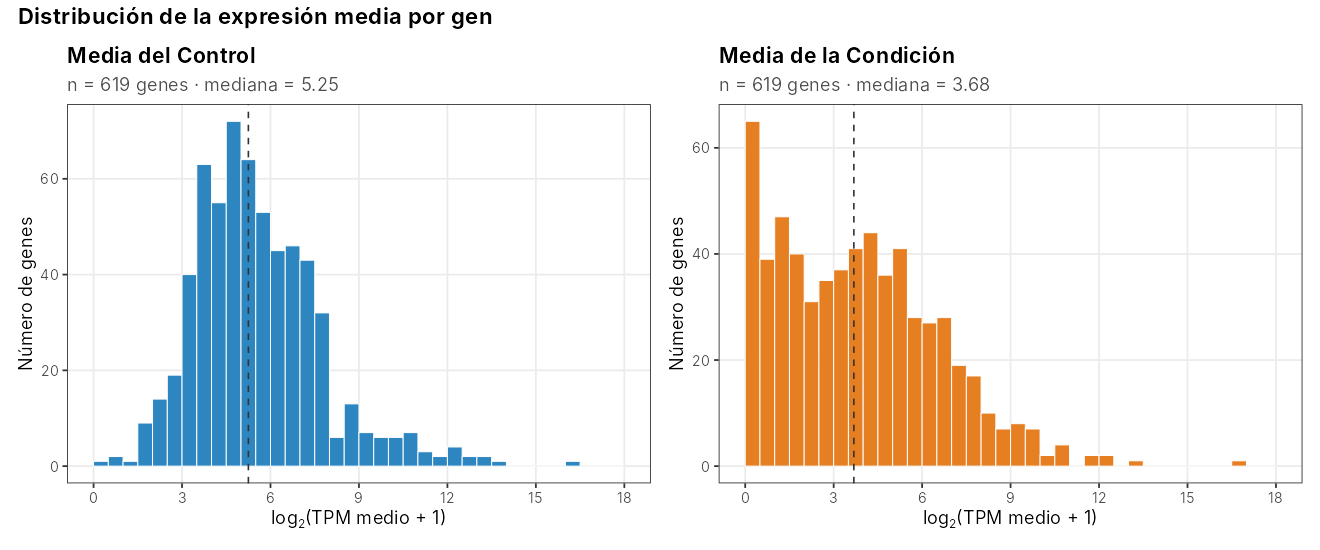

In [14]:
fig_histogramas <- (histograma("Control") | histograma("Condición")) +
  plot_annotation(title = "Distribución de la expresión media por gen",
                  theme = theme(plot.title = element_text(face = "bold", size = 15)))
guardar_ggplot(fig_histogramas, "Fig1_Ap3_Histogramas_medias", 12, 5)

## Apartado 4
4.- En una sola imagen, muestra un boxplot para la condición y otro para el control.  
Añade el título, colores y una una leyenda en la esquina superior izquierda. ( 1,5 pto)

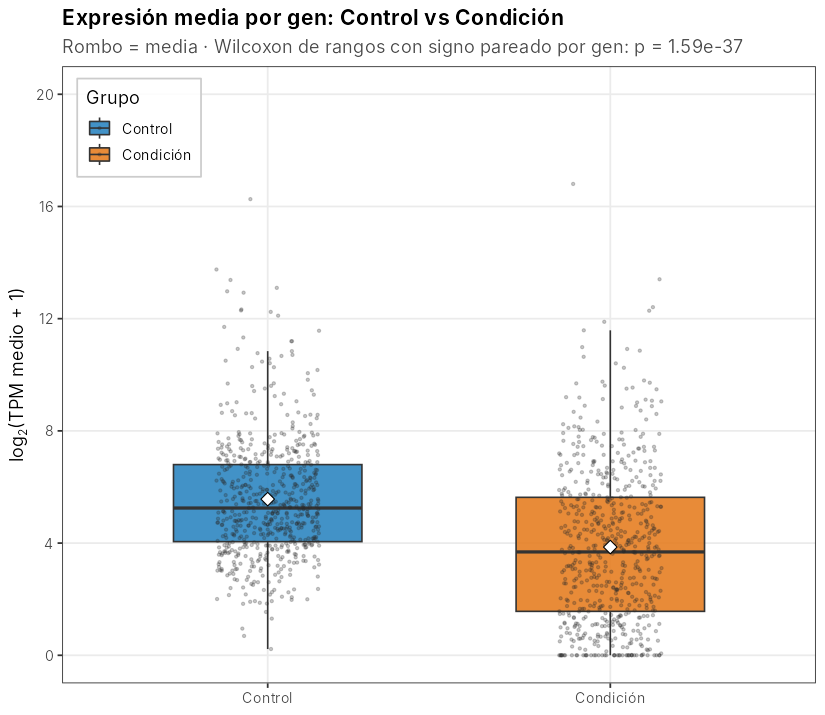

In [15]:
p_pareado <- wilcox.test(tabla$Media_Control, tabla$Media_Condicion, paired = TRUE)$p.value

fig_boxplot <- ggplot(medias_largo, aes(Grupo, log2Media, fill = Grupo)) +
  geom_boxplot(width = 0.55, outlier.shape = NA, alpha = 0.9) +
  geom_jitter(width = 0.15, height = 0, size = 0.7, alpha = 0.25, colour = "grey15") +
  stat_summary(fun = mean, geom = "point", shape = 23, size = 3, fill = "white") +
  scale_fill_manual(values = colores_grupo, name = "Grupo") +
  scale_y_continuous(limits = c(0, 20), breaks = seq(0, 20, 4)) +
  labs(title = "Expresión media por gen: Control vs Condición",
       subtitle = sprintf("Rombo = media · Wilcoxon de rangos con signo pareado por gen: p = %.2e", p_pareado),
       x = NULL, y = expression(log[2]*"(TPM medio + 1)")) +
  tema + leyenda_sup_izq()
guardar_ggplot(fig_boxplot, "Fig2_Ap4_Boxplot_Control_vs_Condicion", 7.5, 6.5)

## Apartado 5
5.- Evalúa la normalidad de Control y Condición y acorde con los resultados, haz lo siguiente: (2 pto)  
Realiza un test de comparativa de medias para cada gen entre condición y control.  
Guarda el p-value de la comparativa y anádelo como una columna extra a tu tabla original.



Grupo       Escala                W   p_value  Normal 
----------  --------------  -------  --------  -------
Control     TPM              0.0685         0  FALSE  
Control     log2(TPM + 1)    0.9512         0  FALSE  
Condición   TPM              0.0329         0  FALSE  
Condición   log2(TPM + 1)    0.9574         0  FALSE  

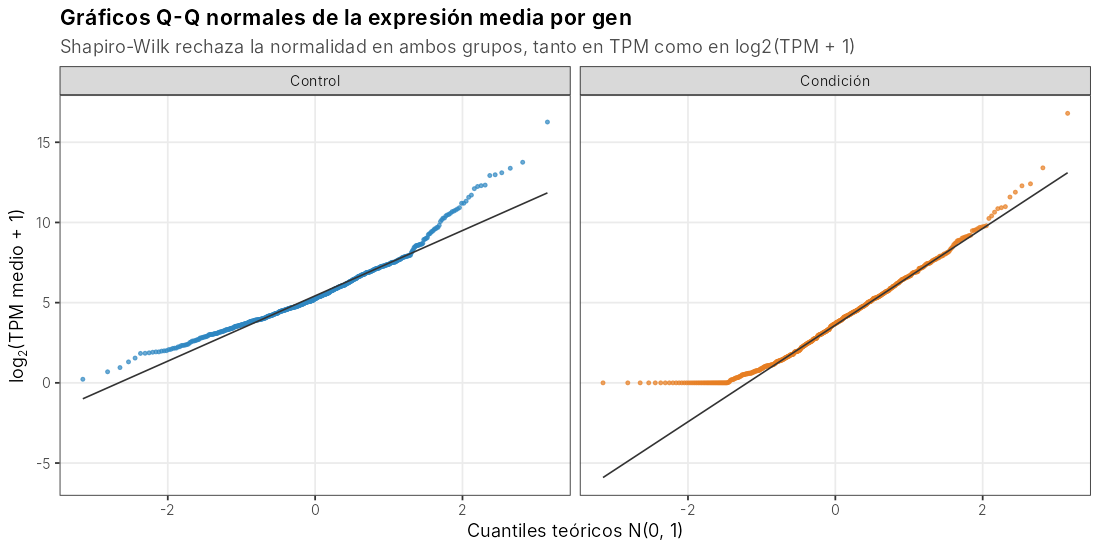

In [16]:
normalidad_global <- rbindlist(lapply(c("Control", "Condición"), function(g) {
  v <- medias_largo[Grupo == g]
  data.table(Grupo = g,
             Escala = c("TPM", "log2(TPM + 1)"),
             W = c(shapiro.test(v$Media)$statistic, shapiro.test(v$log2Media)$statistic),
             p_value = c(shapiro.test(v$Media)$p.value, shapiro.test(v$log2Media)$p.value))
}))
normalidad_global[, Normal := p_value > CONFIG$alpha]
knitr::kable(normalidad_global, digits = 4, format = "simple")

fig_qq <- ggplot(medias_largo, aes(sample = log2Media, colour = Grupo)) +
  stat_qq(size = 0.9, alpha = 0.7) + stat_qq_line(colour = "grey20") +
  facet_wrap(~ Grupo) +
  scale_colour_manual(values = colores_grupo, guide = "none") +
  labs(title = "Gráficos Q-Q normales de la expresión media por gen",
       subtitle = "Shapiro-Wilk rechaza la normalidad en ambos grupos, tanto en TPM como en log2(TPM + 1)",
       x = "Cuantiles teóricos N(0, 1)", y = expression(log[2]*"(TPM medio + 1)")) +
  tema
guardar_ggplot(fig_qq, "Fig3_Ap5_QQ_normalidad", 10, 5)

In [17]:
resultados <- t(vapply(
  seq_len(nrow(tabla)),
  function(i) tryCatch(comparar_gen(m_control[i, ], m_condicion[i, ], CONFIG$alpha),
                       error = function(e) rep(NA_real_, 6)),
  numeric(6)
))
if (anyNA(resultados[, 6])) warning("Hay genes sin p-value calculable.")

tabla[, `:=`(Shapiro_p_Control   = resultados[, 1],
             Shapiro_p_Condicion = resultados[, 2],
             F_varianzas_p       = resultados[, 3],
             Test                = factor(etiquetas_test[resultados[, 4]], levels = etiquetas_test),
             Estadistico         = resultados[, 5],
             p_value             = resultados[, 6])]
tabla[, p_adj_BH := p.adjust(p_value, method = "BH")]
tabla[, log2FC := log2((Media_Condicion + CONFIG$pseudo) / (Media_Control + CONFIG$pseudo))]

In [18]:
resumen_tests <- tabla[, .(Genes = .N,
                           p_minimo = min(p_value),
                           p_menor_0.05 = sum(p_value < CONFIG$alpha)), by = Test][order(Test)]
knitr::kable(resumen_tests, digits = 4, format = "simple")

p_suelo_wilcoxon <- c(exacto = wilcox.test(1:3, 4:6)$p.value,
                      aproximado = suppressWarnings(wilcox.test(1:3, 4:6, exact = FALSE)$p.value))
p_suelo_wilcoxon

head(tabla[, c(CONFIG$col_gen, "Media_Control", "Media_Condicion", "Test", "p_value", "p_adj_BH"),
           with = FALSE])
dim(tabla)



Test                 Genes   p_minimo   p_menor_0.05
------------------  ------  ---------  -------------
t de Student           262     0.0000            145
t de Welch              48     0.0004             32
U de Mann-Whitney      309     0.0636              0

exacto aproximado 
 0.1000000  0.0808556

Gene Name,Media_Control,Media_Condicion,Test,p_value,p_adj_BH
<chr>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>
urtA,32.48754,0.000000,U de Mann-Whitney,0.0636025696,0.109999155
recQ,105.53724,5.644567,U de Mann-Whitney,0.0808555984,0.109999155
kdsA,59.29588,4.083638,U de Mann-Whitney,0.0765225005,0.109999155
lysA,122.03863,26.979127,t de Student,0.0001476687,0.003808622
sir,156.02125,4.770760,U de Mann-Whitney,0.0808555984,0.109999155
map,54.10653,1.867688,U de Mann-Whitney,0.0765225005,0.109999155


[1] 619  19

## Apartado 6
6.- De los resultados del apartado 5, saca (mediante código) un listado de los genes diferencialmente expresados (aquellos que tengan un pvalue < 0.05)  
¿Cuántos genes tienes? Sino te sale ninguno, justifica por qué. En caso de que sí que te salgan, ¿cuántos salen sobreexpresados y cuántos reprimidos? (1 pto)

In [19]:
tabla[, Regulacion := fifelse(p_value < CONFIG$alpha,
                              fifelse(Media_Condicion > Media_Control, "Sobreexpresado", "Reprimido"),
                              "No significativo")]
deg <- tabla[p_value < CONFIG$alpha][order(p_value)]

listado_deg <- deg[[CONFIG$col_gen]]
listado_deg

n_deg   <- nrow(deg)
n_sobre <- deg[Regulacion == "Sobreexpresado", .N]
n_repr  <- deg[Regulacion == "Reprimido", .N]
n_bh    <- tabla[p_adj_BH < CONFIG$alpha, .N]

[1] "htpG"  "rpmI"  "sixA"  "smc"   "murJ"  "sufB"  "psbU"  "rpsT"  "rpmA"  "sufC"  "recA"  "gmk"   "ppk1"  "uvrB"  "zwf"   "cysE"  "ftsH4" "nudC"  "dnaN"  "psaX"  "psbQ"  "bchL"  "rpsP"  "lysA" 
 [25] "cphA"  "rpmE"  "argB"  "nadA"  "rpsL"  "dnaG"  "queF"  "psaI"  "purB"  "purU"  "rplC"  "rplE"  "nrdJ"  "murC"  "fetB"  "rbfA"  "xylB"  "rpsF"  "fbp"   "dapA"  "cysW"  "tyrS"  "bchB"  "psb28"
 [49] "psb29" "uvrC"  "ndhC"  "gntK"  "recR"  "gshB"  "aroA"  "ffh"   "groES" "cpdA"  "ligA"  "dusB"  "aqpZ"  "rplA"  "cimA"  "kdsB"  "rsmD"  "pheA"  "lepA"  "psbD"  "hemH"  "ftsY"  "rplF"  "rplK" 
 [73] "mrdA"  "gcvP"  "aroQ"  "mltG"  "glmS"  "apcA"  "dnaB"  "sufR"  "hydA"  "rpsJ"  "pds"   "larE"  "trpB"  "cdaA"  "alaS"  "tal"   "secA"  "infC"  "ispD"  "atpH"  "hemF"  "rnpB"  "gatB"  "nadB" 
 [97] "uvrA"  "dnaA"  "polA"  "truB"  "mutL"  "psbF"  "psb27" "psaC"  "rodA"  "yqeK"  "secG"  "glgA"  "arsM"  "acnB"  "lgt"   "ileS"  "mdh"   "wecB"  "recG"  "cobN"  "deoC"  "psaK"  "rpe"   "pheT" 
[121] "glgB"  "menB"  "tilS"  "rpsB"  "rplU"  "glyS"  "rpoB"  "tsf"   "minC"  "aat"   "frr"   "mfd"   "rplL"  "katG"  "thiC"  "argH"  "cpcA"  "guaA"  "grxD"  "rplX"  "rplD"  "rpmH"  "dhaL"  "nuoK" 
[145] "aroF"  "lexA"  "urtE"  "recF"  "pdxH"  "cobO"  "malQ"  "typA"  "rpsE"  "rplQ"  "rimP"  "ptsP"  "fabF"  "argS"  "asnB"  "prmC"  "acpP"  "cobS"  "murQ"  "gpmI"  "rplO"  "raiA"  "ald"   "rlmN" 
[169] "mreD"  "gshA"  "cofG"  "atpA"  "gatA"  "rpsS"  "rpmC"  "thiO"  "nuoH"

In [20]:
cat(sprintf("Genes diferencialmente expresados (p-value < %.2f): %d de %d (%.1f %%)\n",
            CONFIG$alpha, n_deg, nrow(tabla), 100 * n_deg / nrow(tabla)),
    sprintf("  Sobreexpresados en la Condición: %d\n", n_sobre),
    sprintf("  Reprimidos en la Condición:      %d\n", n_repr),
    sprintf("  Significativos tras corrección de Benjamini-Hochberg (FDR < %.2f): %d\n",
            CONFIG$alpha, n_bh), sep = "")

table(Regulacion = deg$Regulacion, Test = droplevels(deg$Test))

knitr::kable(deg[, c(CONFIG$col_gen, "Media_Control", "Media_Condicion", "log2FC",
                     "Test", "p_value", "p_adj_BH", "Regulacion"), with = FALSE],
             digits = 4, format = "simple")

Genes diferencialmente expresados (p-value < 0.05): 177 de 619 (28.6 %)
  Sobreexpresados en la Condición: 48
  Reprimidos en la Condición:      129
  Significativos tras corrección de Benjamini-Hochberg (FDR < 0.05): 111


                Test
Regulacion       t de Student t de Welch
  Reprimido               105         24
  Sobreexpresado           40          8



Gene Name    Media_Control   Media_Condicion    log2FC  Test            p_value   p_adj_BH  Regulacion     
----------  --------------  ----------------  --------  -------------  --------  ---------  ---------------
htpG               75.1485           12.0240   -2.5476  t de Student     0.0000     0.0001  Reprimido      
rpmI              823.8143           84.6659   -3.2673  t de Student     0.0000     0.0004  Reprimido      
sixA               22.3155          241.8318    3.3806  t de Student     0.0000     0.0004  Sobreexpresado 
smc                41.2663            3.7165   -3.1637  t de Student     0.0000     0.0006  Reprimido      
murJ               47.3467          176.7211    1.8781  t de Student     0.0000     0.0006  Sobreexpresado 
sufB              396.1237         1936.5258    2.2866  t de Student     0.0000     0.0013  Sobreexpresado 
psbU             2571.8889          145.6027   -4.1334  t de Student     0.0000     0.0019  Reprimido      
rpsT             1835.5020

In [21]:
tabla[, Regulacion := factor(Regulacion, levels = c("Sobreexpresado", "Reprimido", "No significativo"))]
colores_reg <- c(Sobreexpresado = CONFIG$col_condicion, Reprimido = CONFIG$col_control,
                 "No significativo" = "grey75")
top_genes <- deg[1:min(15, n_deg)]

fig_volcano <- ggplot(tabla, aes(log2FC, -log10(p_value), colour = Regulacion)) +
  geom_point(size = 1.6, alpha = 0.8) +
  geom_hline(yintercept = -log10(CONFIG$alpha), linetype = "dashed", colour = "grey30") +
  geom_vline(xintercept = 0, colour = "grey60") +
  ggrepel::geom_text_repel(data = top_genes, aes(label = get(CONFIG$col_gen)),
                           size = 3, max.overlaps = Inf, show.legend = FALSE, seed = 1) +
  scale_colour_manual(values = colores_reg, name = NULL,
                      labels = c(sprintf("Sobreexpresados (%d)", n_sobre),
                                 sprintf("Reprimidos (%d)", n_repr),
                                 sprintf("No significativos (%d)", nrow(tabla) - n_deg))) +
  labs(title = "Volcano plot", subtitle = "Línea discontinua: p = 0.05",
       x = expression(log[2]*" Fold Change (Condición / Control)"),
       y = expression(-log[10]*"(p-value)")) +
  tema + leyenda_sup_izq()

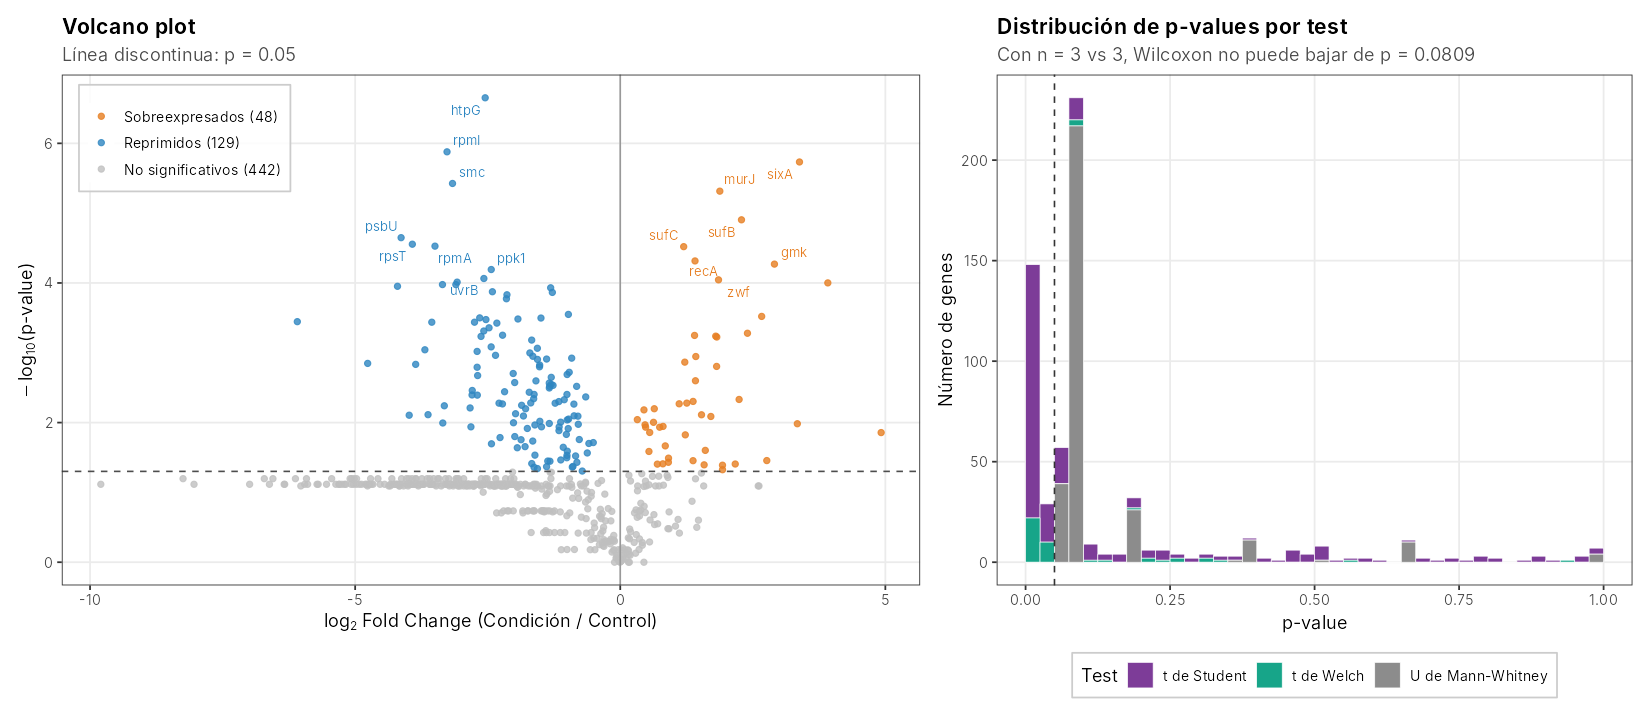

In [22]:
fig_pvalores <- ggplot(tabla, aes(p_value, fill = Test)) +
  geom_histogram(binwidth = 0.025, boundary = 0, colour = "white", linewidth = 0.2) +
  geom_vline(xintercept = CONFIG$alpha, linetype = "dashed", colour = "grey20") +
  scale_fill_manual(values = c("#7D3C98", "#17A589", "grey55"), name = "Test") +
  labs(title = "Distribución de p-values por test",
       subtitle = sprintf("Con n = 3 vs 3, Wilcoxon no puede bajar de p = %.4f", p_suelo_wilcoxon[["aproximado"]]),
       x = "p-value", y = "Número de genes") +
  tema + theme(legend.position = "bottom")

guardar_ggplot(fig_volcano + fig_pvalores + plot_layout(widths = c(1.35, 1)),
               "Fig4_Ap6_Volcano_y_pvalues", 15, 6.5)

In [23]:
fwrite(deg[, c(CONFIG$col_gen, CONFIG$control, CONFIG$condicion, "Media_Control", "DE_Control",
               "Media_Condicion", "DE_Condicion", "log2FC", "Test", "p_value", "p_adj_BH",
               "Regulacion"), with = FALSE],
       file.path(CONFIG$dir_tab, "Genes_diferencialmente_expresados.tsv"), sep = "\t")

## Apartado 7
7.- Por último, realiza un heatmap de los genes diferencialmente expresados  
Emplea la Práctica de R como referencia. (2 pts)

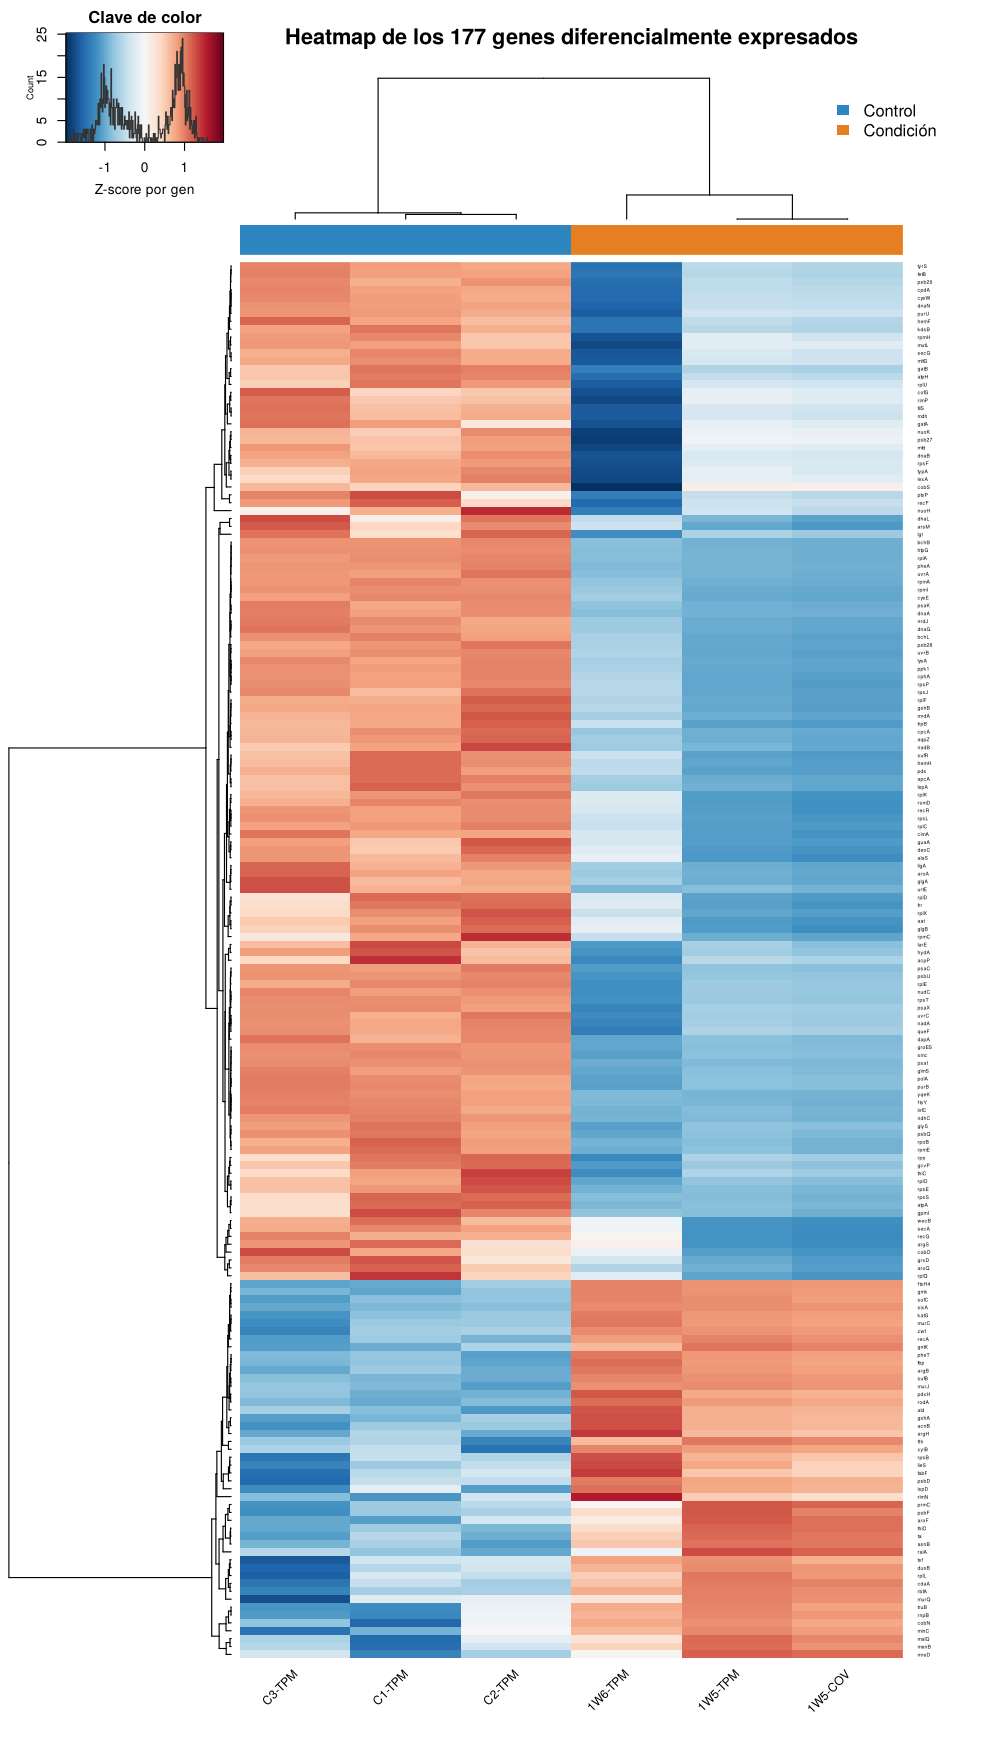

In [24]:
matriz_deg <- log2(as.matrix(deg[, c(CONFIG$control, CONFIG$condicion), with = FALSE]) + CONFIG$pseudo)
rownames(matriz_deg) <- deg[[CONFIG$col_gen]]

rowv <- as.dendrogram(hclust(as.dist(1 - cor(t(matriz_deg))), method = "average"))
colv <- as.dendrogram(hclust(as.dist(1 - cor(matriz_deg)), method = "average"))
paleta_heatmap <- colorRampPalette(rev(RColorBrewer::brewer.pal(11, "RdBu")))(256)

dibujar_heatmap <- function() {
  heatmap.2(matriz_deg, Rowv = rowv, Colv = colv, scale = "row",
            col = paleta_heatmap, trace = "none",
            ColSideColors = rep(c(CONFIG$col_control, CONFIG$col_condicion),
                                c(length(CONFIG$control), length(CONFIG$condicion))),
            density.info = "histogram", denscol = "grey20",
            key.title = "Clave de color", key.xlab = "Z-score por gen",
            cexCol = 1, cexRow = 0.42, srtCol = 45, margins = c(7, 6),
            lhei = c(1.2, 8), lwid = c(1.6, 5),
            main = sprintf("Heatmap de los %d genes diferencialmente expresados", n_deg))
  legend("topright", legend = names(colores_grupo), fill = colores_grupo,
         border = NA, bty = "n", cex = 0.9, inset = c(0, 0), xpd = TRUE)
}
guardar_base(dibujar_heatmap, "Fig5_Ap7_Heatmap_DEG", 9, 16)

## Anexo. Control de calidad de las muestras, análisis de sensibilidad y exportación

,C1-TPM,C2-TPM,C3-TPM,1W5-TPM,1W6-TPM,1W5-COV
C1-TPM,1.0000,0.9647,0.9626,0.6263,0.7282,0.6273
C2-TPM,0.9647,1.0000,0.9587,0.6211,0.7324,0.6221
C3-TPM,0.9626,0.9587,1.0000,0.5949,0.6981,0.5958
1W5-TPM,0.6263,0.6211,0.5949,1.0000,0.8291,1.0000
1W6-TPM,0.7282,0.7324,0.6981,0.8291,1.0000,0.8300
1W5-COV,0.6273,0.6221,0.5958,1.0000,0.8300,1.0000


1W5-COV / 1W5-TPM: media = 0.957963, DE = 1.35e-07, r de Pearson = 1.000000


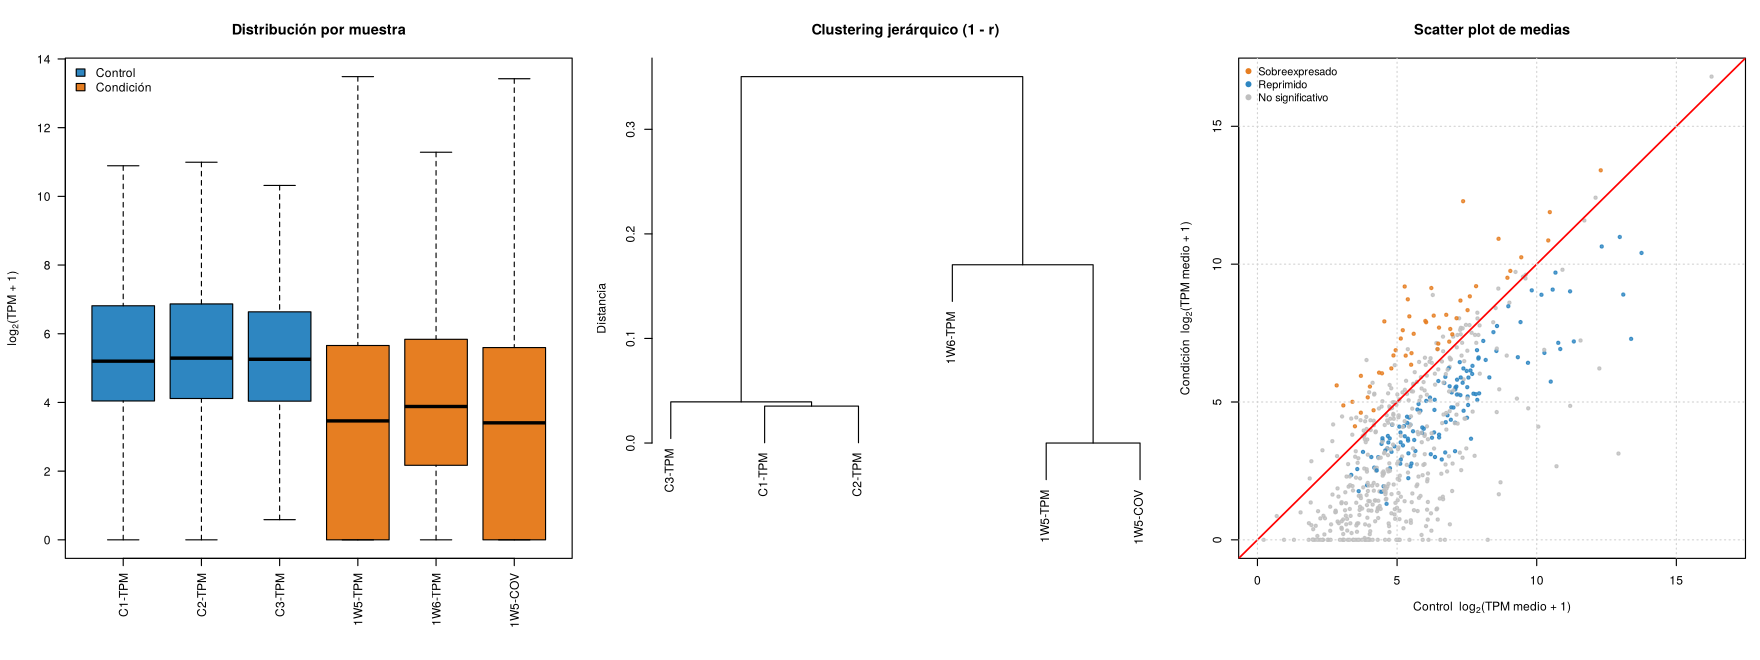

In [25]:
matriz_log <- log2(cbind(m_control, m_condicion) + CONFIG$pseudo)
correlaciones <- cor(matriz_log)
round(correlaciones, 4)

razon_cov <- tabla[`1W5-TPM` > 0, `1W5-COV` / `1W5-TPM`]
cat(sprintf("1W5-COV / 1W5-TPM: media = %.6f, DE = %.2e, r de Pearson = %.6f\n",
            mean(razon_cov), sd(razon_cov), cor(tabla$`1W5-TPM`, tabla$`1W5-COV`)))

dibujar_qc <- function() {
  op <- par(mfrow = c(1, 3), mar = c(7, 4.5, 4, 1))
  on.exit(par(op))
  boxplot(matriz_log, col = rep(colores_grupo, each = 3), las = 2, outline = FALSE,
          main = "Distribución por muestra", ylab = expression(log[2]*"(TPM + 1)"))
  legend("topleft", legend = names(colores_grupo), fill = colores_grupo, bty = "n")
  plot(hclust(as.dist(1 - correlaciones), method = "average"), xlab = "", sub = "",
       main = "Clustering jerárquico (1 - r)", ylab = "Distancia")
  lim <- c(0, max(log2(c(tabla$Media_Control, tabla$Media_Condicion) + CONFIG$pseudo)))
  plot(log2(tabla$Media_Control + CONFIG$pseudo), log2(tabla$Media_Condicion + CONFIG$pseudo),
       pch = 19, cex = 0.6, col = adjustcolor(colores_reg[as.character(tabla$Regulacion)], 0.8),
       xlim = lim, ylim = lim, main = "Scatter plot de medias",
       xlab = expression("Control  " * log[2]*"(TPM medio + 1)"),
       ylab = expression("Condición  " * log[2]*"(TPM medio + 1)"))
  abline(0, 1, col = "red", lwd = 1.5)
  grid()
  legend("topleft", legend = names(colores_reg), col = colores_reg, pch = 19, bty = "n", cex = 0.9)
}
guardar_base(dibujar_qc, "FigS1_QC_muestras", 16, 6)

In [26]:
p_welch_3v3 <- welch_vectorizado(log2(m_control + CONFIG$pseudo), log2(m_condicion + CONFIG$pseudo))
p_welch_3v2 <- welch_vectorizado(log2(m_control + CONFIG$pseudo),
                                 log2(m_condicion[, c("1W5-TPM", "1W6-TPM")] + CONFIG$pseudo))

resumir_escenario <- function(nombre, p) {
  sig <- !is.na(p) & p < CONFIG$alpha
  data.table(Escenario = nombre,
             p_menor_0.05 = sum(sig),
             FDR_BH_menor_0.05 = sum(p.adjust(p, "BH") < CONFIG$alpha, na.rm = TRUE),
             Coinciden_con_principal = sum(sig & tabla$p_value < CONFIG$alpha))
}

In [27]:
sensibilidad <- rbind(
  resumir_escenario("Principal: test según normalidad (3 vs 3, TPM)", tabla$p_value),
  resumir_escenario("Welch sobre log2(TPM + 1) (3 vs 3)", p_welch_3v3),
  resumir_escenario("Welch sobre log2(TPM + 1) sin 1W5-COV (3 vs 2)", p_welch_3v2)
)
knitr::kable(sensibilidad, format = "simple")

fwrite(tabla, file.path(CONFIG$dir_tab, "Tabla_completa_resultados.tsv"), sep = "\t")
fwrite(normalidad_global, file.path(CONFIG$dir_tab, "Normalidad_global_Shapiro.tsv"), sep = "\t")
fwrite(resumen_tests, file.path(CONFIG$dir_tab, "Resumen_tests_por_gen.tsv"), sep = "\t")
fwrite(sensibilidad, file.path(CONFIG$dir_tab, "Analisis_sensibilidad.tsv"), sep = "\t")
writeLines(capture.output(sessionInfo()), file.path(CONFIG$dir_tab, "sessionInfo.txt"))



Escenario                                         p_menor_0.05   FDR_BH_menor_0.05   Coinciden_con_principal
-----------------------------------------------  -------------  ------------------  ------------------------
Principal: test según normalidad (3 vs 3, TPM)             177                 111                       177
Welch sobre log2(TPM + 1) (3 vs 3)                         322                 211                       152
Welch sobre log2(TPM + 1) sin 1W5-COV (3 vs 2)             156                  45                        90

In [28]:
list.files("resultados", recursive = TRUE)

rm(resultados, medias_largo, medianas, matriz_log, razon_cov, p_welch_3v3, p_welch_3v2)
invisible(gc())

[1] "figuras/Fig1_Ap3_Histogramas_medias.pdf"           "figuras/Fig1_Ap3_Histogramas_medias.png"           "figuras/Fig2_Ap4_Boxplot_Control_vs_Condicion.pdf"
 [4] "figuras/Fig2_Ap4_Boxplot_Control_vs_Condicion.png" "figuras/Fig3_Ap5_QQ_normalidad.pdf"                "figuras/Fig3_Ap5_QQ_normalidad.png"               
 [7] "figuras/Fig4_Ap6_Volcano_y_pvalues.pdf"            "figuras/Fig4_Ap6_Volcano_y_pvalues.png"            "figuras/Fig5_Ap7_Heatmap_DEG.pdf"                 
[10] "figuras/Fig5_Ap7_Heatmap_DEG.png"                  "figuras/FigS1_QC_muestras.pdf"                     "figuras/FigS1_QC_muestras.png"                    
[13] "tablas/Analisis_sensibilidad.tsv"                  "tablas/Genes_diferencialmente_expresados.tsv"      "tablas/Normalidad_global_Shapiro.tsv"             
[16] "tablas/Resumen_tests_por_gen.tsv"                  "tablas/sessionInfo.txt"                            "tablas/Tabla_completa_resultados.tsv"